> **学生作业版说明**  
> 本 Notebook 为学生作业版，部分关键代码单元已被替换为待补全骨架。  
> 请结合 `README.md`、`assignment.md` 与 `starter.py` 完成实验。  
> 提交前请确认：代码可运行、指标齐全、报告完整。

### 概述
&ensp;&ensp;本实验介绍Logistic回归具体应用。

### 实验环境
+ Ubuntu
+ Jupyter NoteBook

### 实验目标
完成本实验后，您能够

1. 通过本实验进一步掌握Logistic回归回归算法的原理。
2. 掌握如何使用Logistic回归解决实际问题。
3. 掌握使用机器学习方法解决现实世界问题的流程。

### 任务：Logistic回归
#### 【任务目标】
本次实战内容，将使用Logistic回归来预测患疝气病的马的存活问题，数据集已经下载好了，放在当前实验的数据集目录下，可直接使用。
这里的数据包含了368个样本和28个特征。疝气病不一定源自马的肠胃问题，其他问题也可能引发马疝病。该数据集中包含了医院检测马疝病的一些指标，有的指标比较主观，有的指标难以测量，例如马的疼痛级别。另外需要说明的是，除了部分指标主观和难以测量外，该数据还存在一个问题，数据集中有30%的值是缺失的。下面将首先介绍如何处理数据集中的数据缺失问题，然后再利用Logistic回归和随机梯度上升算法来预测病马的生死。
#### 【任务步骤】
1. 数据准备
2. 利用梯度上升算法得到回归系数
3. 进行预测
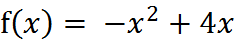
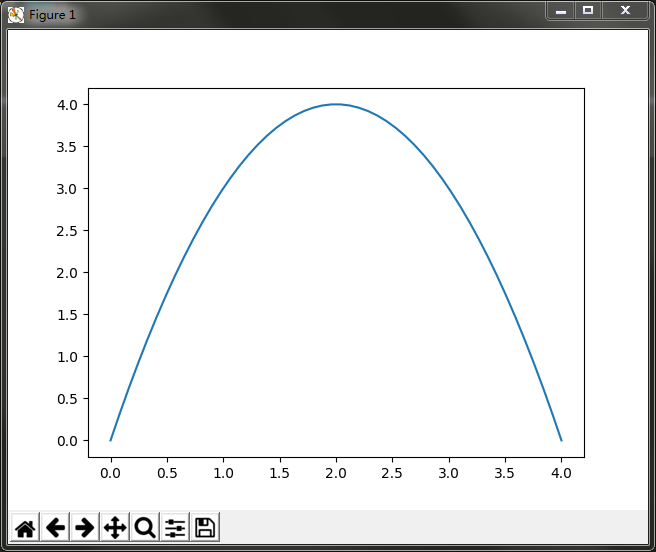
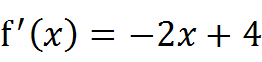
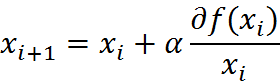
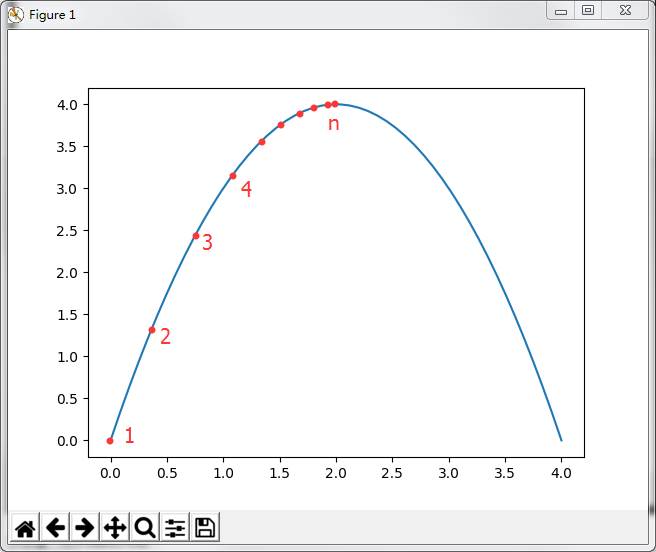

### 1. 准备数据

数据中的缺失值是一个非常棘手的问题，很多文献都致力于解决这个问题。那么，数据缺失究竟带来了什么问题？假设有100个样本和20个特征，这些数据都是机器收集回来的。若机器上的某个传感器损坏导致一个特征无效时该怎么办？它们是否还可用？答案是肯定的。因为有时候数据相当昂贵，扔掉和重新获取都是不可取的，所以必须采用一些方法来解决这个问题。下面给出了一些可选的做法：

* 使用可用特征的均值来填补缺失值；
* 使用特殊值来填补缺失值，如-1；
* 忽略有缺失值的样本；
* 使用相似样本的均值添补缺失值；
* 使用另外的机器学习算法预测缺失值。

预处理数据做两件事：

* 如果测试集中一条数据的特征值已经确实，那么我们选择实数0来替换所有缺失值，因为本文使用Logistic回归。因此这样做不会影响回归系数的值。sigmoid(0)=0.5，即它对结果的预测不具有任何倾向性。
* 如果测试集中一条数据的类别标签已经缺失，那么我们将该类别数据丢弃，因为类别标签与特征不同，很难确定采用某个合适的值来替换。

原始的数据集经过处理，保存为两个文件：horseColicTest.txt和horseColicTraining.txt。有了这些数据集，我们只需要一个Logistic分类器，就可以利用该分类器来预测病马的生死问题了。

### 2. 利用梯度上升算法得到回归系数

#### 【梯度上升算法介绍】
梯度上升算法是什么？J(θ)太复杂，我们先看个简单的求极大值的例子：
![16_lr_horse.png](16_lr_horse.png)
这个函数的极值怎么求？显然这个函数开口向下，存在极大值，它的函数图像为：
![17_lr_horse.png](17_lr_horse.png)
求极值，先求函数的导数：
![18_lr_horse.png](18_lr_horse.png)
令导数为0，可求出x=2即取得函数f(x)的极大值。极大值等于f(2)=4
但是真实环境中的函数不会像上面这么简单，就算求出了函数的导数，也很难精确计算出函数的极值。此时我们就可以用迭代的方法来做。就像爬坡一样，一点一点逼近极值。这种寻找最佳拟合参数的方法，就是最优化算法。爬坡这个动作用数学公式表达即为：
![19_lr_horse.png](19_lr_horse.png)
其中，α为步长，也就是学习速率，控制更新的幅度。效果如下图所示：
![20_lr_horse.png](20_lr_horse.png)
比如从(0,0)开始，迭代路径就是1->2->3->4->…->n，直到求出的x为函数极大值的近似值，停止迭代。我们可以编写Python3代码，来实现这一过程：

In [1]:
#导入程序必要的包
import numpy as np
import matplotlib.pyplot as plt
import random
from sklearn.linear_model import LogisticRegression

In [2]:
import os, urllib.request
base = 'https://raw.githubusercontent.com/Heptazero/ml-course-labs/main/machine-learning/homework/'
for name in ['horseColicTraining.txt', 'horseColicTest.txt', 'classification_metrics.py']:
    if not os.path.exists(name):
        urllib.request.urlretrieve(base + name, name)

In [3]:
"""
函数说明:sigmoid函数

Parameters:
    inX - 数据
Returns:
    sigmoid函数
"""
def sigmoid(inX):
    return 1.0 / (1 + np.exp(-inX))



In [4]:
"""
函数说明:梯度上升算法

Parameters:
    dataMatrix  - 数据数组
    classLabels - 数据标签
    alpha       - 学习率
    numIter     - 最大迭代次数
Returns:
    weights - 求得的回归系数数组(最优参数)
"""
def stocGradAscent(dataMatrix, classLabels, alpha = 0.001, numIter = 150):
#### Start Code Here ####
    #返回dataMatrix的大小。m为行数,n为列数
    m, n = np.shape(dataMatrix)
     
    #参数初始化weights 
    weights = np.ones(n)
    
    #随机梯度, 循环150,观察是否收敛
    for j in range(numIter):
        dataIndex = list(range(m))
        for i in range(m):
            # i和j的不断增大，导致alpha的值不断减少，但是不为0
            alpha = 4 / (1.0 + j + i) + 0.0001
            
            # 随机产生一个 0～len()之间的一个值
            # random.uniform(x, y) 方法将随机生成下一个实数，它在[x,y]范围内,x是这个范围内的最小值，y是这个范围内的最大值。
            randIndex = int(random.uniform(0, len(dataIndex)))
            k = dataIndex[randIndex]
            
            # sum(dataMatrix[i]*weights)为了求 f(x)的值， f(x)=a1*x1+b2*x2+..+nn*xn
            h = sigmoid(sum(dataMatrix[k] * weights))
                
            #真实值和预测值之间的误差
            error = classLabels[k] - h
            
            #更新回归系数
            weights = weights + alpha * error * dataMatrix[k]
            
            #删除已经使用的样本
            del(dataIndex[randIndex])
            
    return weights
#### End Code Here ####

### 3. 进行预测

In [5]:
"""
函数说明:使用Python写的Logistic分类器做预测

Parameters:
    无
Returns:
    无
"""
def colicTest():
    #打开训练集
    frTrain = open('horseColicTraining.txt') 
    
    #打开测试集
    frTest = open('horseColicTest.txt') 

    #构造数据集trainingSet和标签列trainingLabels，其中最后一列为标签列
    trainingSet = []
    trainingLabels = []
  
    #逐行读取训练文件
    for line in frTrain.readlines():
        #使用strip、split函数先后对行字符进行处理
        currLine = line.strip().split('\t')
        lineArr = []
        for i in range(len(currLine)-1):
            lineArr.append(float(currLine[i]))
            
        #向训练数据集和标签列添加数据    
        trainingSet.append(lineArr)
        trainingLabels.append(float(currLine[-1]))

    #使用改进的随机上升梯度训练
    random.seed(42)
    trainWeights = stocGradAscent(np.array(trainingSet), trainingLabels, numIter=500)
        
    #初始化预测错误的个数和测试集的个数
    errorCount = 0
    numTestVec = 0.0
        
    #逐行读取测试文件
    for line in frTest.readlines():
            #测试样本数量加1
            numTestVec += 1.0
            
            #使用strip、split函数先后对行字符进行处理
            currLine = line.strip().split('\t')
            lineArr =[]
            for i in range(len(currLine)-1):
                lineArr.append(float(currLine[i]))
                
            #预测错误的情况
            if int(classifyVector(np.array(lineArr), trainWeights)) != int(currLine[-1]):
                errorCount += 1
                
    #错误率计算
    errorRate = (float(errorCount) / numTestVec) * 100
        
#### End Code Here #### 
    print("随机梯度上升测试集错误率为: %.2f%%" % errorRate)



"""
函数说明:分类函数

Parameters:
    inX - 特征向量
    weights - 回归系数
Returns:
    分类结果
"""
#把测试集上每个特征向量乘以最优化方法得来的回归系数，再将乘积结果求和
#最后输入到Sigmoid函数中即可。如果对应的Sigmoid值大于0.5就预测类别标签为1，否则为0。
def classifyVector(inX, weights):
#### Start Code Here ####
    prob = sigmoid(sum(inX * weights))
    if prob > 0.5:
        return 1.0
    else:
        return 0.0
#### End Code Here #### 

if __name__ == '__main__':
    colicTest()

/var/folders/f1/b_p6j9nx5l1463498w06lb5h0000gn/T/ipykernel_46155/2198385759.py:10: RuntimeWarning: overflow encountered in exp
  return 1.0 / (1 + np.exp(-inX))


随机梯度上升测试集错误率为: 58.21%


### 补充：读入数据，看每一列的零值

In [6]:
import pandas as pd
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.model_selection import RepeatedStratifiedKFold
from classification_metrics import accuracy_score, precision_score, recall_score, cross_entropy

np.seterr(over='ignore')

def load(path):
    data = np.loadtxt(path)
    return data[:, :-1], data[:, -1]

X_train, y_train = load('horseColicTraining.txt')
X_test, y_test = load('horseColicTest.txt')
print('训练集', X_train.shape, '测试集', X_test.shape)
print('标签为 1 的比例：训练集 %.3f，测试集 %.3f' % (y_train.mean(), y_test.mean()))
print('测试集全部预测为 1 的错误率：%.4f' % (1 - y_test.mean()))
print()
summary = pd.DataFrame({'零值占比': (X_train == 0).mean(axis=0),
                        '最小非零值': [X_train[X_train[:, j] != 0, j].min() for j in range(21)],
                        '最大值': X_train.max(axis=0)})
print(summary.round(3).to_string())

训练集 (299, 21) 测试集 (67, 21)
标签为 1 的比例：训练集 0.595，测试集 0.701
测试集全部预测为 1 的错误率：0.2985

     零值占比  最小非零值    最大值
0   0.000    1.0    2.0
1   0.000    1.0    9.0
2   0.201   35.4   40.8
3   0.080   30.0  184.0
4   0.194    8.0   96.0
5   0.187    1.0    4.0
6   0.231    1.0    4.0
7   0.157    1.0    6.0
8   0.107    1.0    3.0
9   0.184    1.0    5.0
10  0.147    1.0    4.0
11  0.187    1.0    4.0
12  0.348    1.0    3.0
13  0.355    1.0    3.0
14  0.823    1.0    7.5
15  0.341    1.0    4.0
16  0.395    1.0    5.0
17  0.097   23.0   75.0
18  0.110    3.3   89.0
19  0.552    1.0    3.0
20  0.662    0.1   10.1


### 补充：混淆矩阵与 Precision / Recall / F1

In [7]:
def confusion(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    return tp, fp, fn, tn

def report(y_true, y_pred):
    tp, fp, fn, tn = confusion(y_true, y_pred)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn, 'accuracy': (tp + tn) / len(y_true),
            'precision': precision, 'recall': recall, 'specificity': specificity,
            'F1': f1, 'balanced acc': (recall + specificity) / 2}

random.seed(42)
w_raw = stocGradAscent(X_train, y_train, numIter=500)
pred_raw = (sigmoid(X_test.dot(w_raw)) > 0.5).astype(int)
pred_all1 = np.ones(len(y_test), dtype=int)

print('错误率 %.2f%%（与上面 colicTest 一致）' % (100 * np.mean(pred_raw != y_test)))
print(pd.DataFrame({'模板原样': report(y_test, pred_raw), '全部预测为1': report(y_test, pred_all1)}).round(4).to_string())

tp, fp, fn, tn = confusion(y_test, pred_raw)
print()
print('与 sklearn 对照：混淆矩阵一致', np.array_equal(confusion_matrix(y_test, pred_raw), np.array([[tn, fp], [fn, tp]])))
print('与 classification_metrics.py 对照：accuracy %.4f，precision %.4f，recall %.4f' % (
    accuracy_score(y_test, pred_raw), precision_score(y_test, pred_raw), recall_score(y_test, pred_raw)))

错误率 58.21%（与上面 colicTest 一致）
                 模板原样   全部预测为1
TP             8.0000  47.0000
FP             0.0000  20.0000
FN            39.0000   0.0000
TN            20.0000   0.0000
accuracy       0.4179   0.7015
precision      1.0000   0.7015
recall         0.1702   1.0000
specificity    1.0000   0.0000
F1             0.2909   0.8246
balanced acc   0.5851   0.5000

与 sklearn 对照：混淆矩阵一致 True
与 classification_metrics.py 对照：accuracy 0.4179，precision 1.0000，recall 0.1702


### 补充：多个随机种子，以及逐步改进输入特征

             输入特征  错误率均值    标准差     最小     最大  错误率>0.5的次数  AUC均值
         template 0.3301 0.0797 0.2239 0.5970           3 0.7458
         raw+bias 0.3436 0.0910 0.2388 0.6119           4 0.7466
      standardize 0.2770 0.0074 0.2687 0.2836           0 0.7680
     missing→mean 0.2391 0.0021 0.2388 0.2537           0 0.8184
missing+indicator 0.2537 0.0000 0.2537 0.2537           0 0.8017


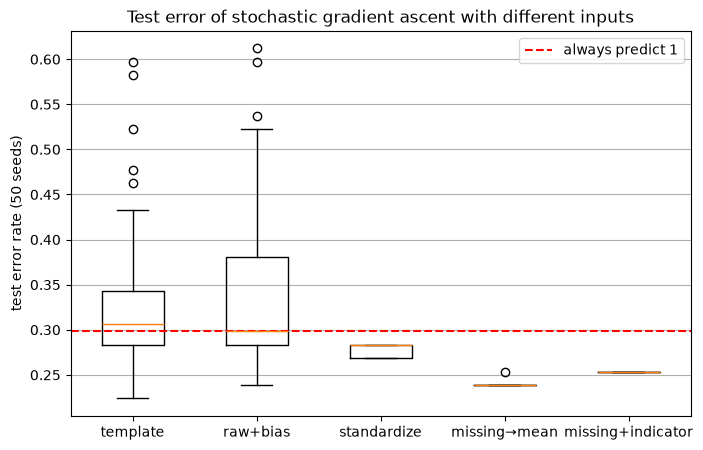

In [8]:
def preprocess(A, B, mode):
    A, B = A.copy(), B.copy()
    if mode == 'template':
        return A, B
    if mode == 'raw+bias':
        mu, sd = np.zeros(A.shape[1]), np.ones(A.shape[1])
        MA, MB = np.zeros(A.shape, bool), np.zeros(B.shape, bool)
    elif mode == 'standardize':
        mu, sd = A.mean(axis=0), A.std(axis=0) + 1e-9
        MA, MB = np.zeros(A.shape, bool), np.zeros(B.shape, bool)
    else:
        MA, MB = A == 0, B == 0
        MA[:, :2], MB[:, :2] = False, False
        mu = np.array([A[~MA[:, j], j].mean() for j in range(A.shape[1])])
        sd = np.array([A[~MA[:, j], j].std() for j in range(A.shape[1])]) + 1e-9
    ZA, ZB = (A - mu) / sd, (B - mu) / sd
    ZA[MA], ZB[MB] = 0, 0
    if mode == 'missing+indicator':
        many = [j for j in range(2, A.shape[1]) if MA[:, j].mean() > 0.3]
        ZA, ZB = np.c_[ZA, MA[:, many]], np.c_[ZB, MB[:, many]]
    return np.c_[np.ones(len(ZA)), ZA], np.c_[np.ones(len(ZB)), ZB]

modes = ['template', 'raw+bias', 'standardize', 'missing→mean', 'missing+indicator']
keys = {'template': 'template', 'raw+bias': 'raw+bias', 'standardize': 'standardize',
        'missing→mean': 'missing', 'missing+indicator': 'missing+indicator'}

def fit_eval(A, ya, B, yb, seed, numIter=500):
    random.seed(seed)
    w = stocGradAscent(A, ya, numIter=numIter)
    prob = sigmoid(B.dot(w))
    return w, prob, np.mean((prob > 0.5) != yb), roc_auc_score(yb, prob)

results = {}
for mode in modes:
    A, B = preprocess(X_train, X_test, keys[mode])
    out = [fit_eval(A, y_train, B, y_test, s)[2:] for s in range(50)]
    results[mode] = np.array(out)

rows = []
for mode in modes:
    r = results[mode]
    rows.append((mode, r[:, 0].mean(), r[:, 0].std(), r[:, 0].min(), r[:, 0].max(), (r[:, 0] > 0.5).sum(), r[:, 1].mean()))
print(pd.DataFrame(rows, columns=['输入特征', '错误率均值', '标准差', '最小', '最大', '错误率>0.5的次数', 'AUC均值']).round(4).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.boxplot([results[m][:, 0] for m in modes])
plt.xticks(range(1, len(modes) + 1), modes)
plt.axhline(1 - y_test.mean(), color='red', linestyle='--', label='always predict 1')
plt.ylabel('test error rate (50 seeds)')
plt.title('Test error of stochastic gradient ascent with different inputs')
plt.legend()
plt.grid(True, axis='y')
plt.show()

### 补充：收敛情况

template input             numIter=1    训练交叉熵 8.5854 ± 1.1293
template input             numIter=10   训练交叉熵 7.8632 ± 1.1622


template input             numIter=100  训练交叉熵 6.5873 ± 0.4390


template input             numIter=500  训练交叉熵 6.4896 ± 1.7308


template input             sklearn 最优解的训练交叉熵 0.5218
missing -> mean, with bias numIter=1    训练交叉熵 1.8863 ± 0.5930
missing -> mean, with bias numIter=10   训练交叉熵 0.4938 ± 0.0086


missing -> mean, with bias numIter=100  训练交叉熵 0.4730 ± 0.0005


missing -> mean, with bias numIter=500  训练交叉熵 0.4721 ± 0.0000
missing -> mean, with bias sklearn 最优解的训练交叉熵 0.4720


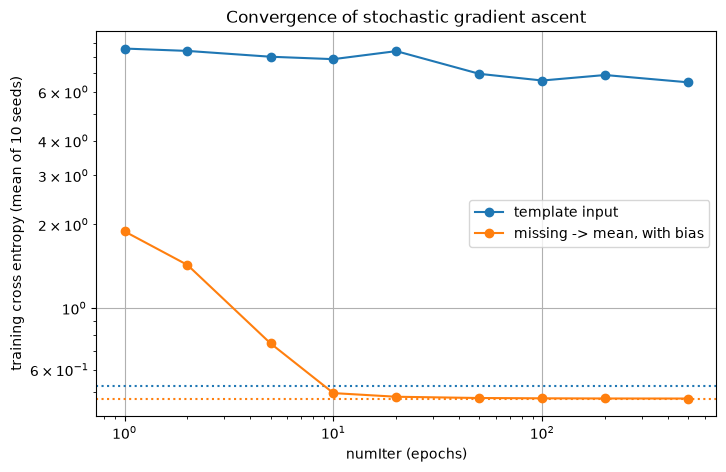

In [9]:
def train_loss(A, y, w):
    return cross_entropy(y, np.clip(sigmoid(A.dot(w)), 1e-12, 1 - 1e-12))

grid = [1, 2, 5, 10, 20, 50, 100, 200, 500]
A_raw, B_raw = preprocess(X_train, X_test, 'template')
A_fin, B_fin = preprocess(X_train, X_test, 'missing')

plt.figure(figsize=(8, 5))
for label, A, fit_int in [('template input', A_raw, False), ('missing -> mean, with bias', A_fin, True)]:
    mean, std = [], []
    for k in grid:
        ls = []
        for s in range(10):
            random.seed(s)
            ls.append(train_loss(A, y_train, stocGradAscent(A, y_train, numIter=k)))
        mean.append(np.mean(ls)); std.append(np.std(ls))
        if k in (1, 10, 100, 500):
            print('%-26s numIter=%-4d 训练交叉熵 %.4f ± %.4f' % (label, k, mean[-1], std[-1]))
    lr = LogisticRegression(C=1e8, fit_intercept=False, max_iter=20000).fit(A, y_train)
    best = train_loss(A, y_train, lr.coef_.ravel())
    print('%-26s sklearn 最优解的训练交叉熵 %.4f' % (label, best))
    line, = plt.plot(grid, mean, marker='o', label=label)
    plt.axhline(best, color=line.get_color(), linestyle=':')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('numIter (epochs)')
plt.ylabel('training cross entropy (mean of 10 seeds)')
plt.title('Convergence of stochastic gradient ascent')
plt.legend()
plt.grid(True)
plt.show()

### 补充：训练集和测试集合并后做 5 折 × 4 次交叉验证

In [10]:
X_all, y_all = np.r_[X_train, X_test], np.r_[y_train, y_test]
splitter = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=0)
cv_rows = []
fold_err = {}
for mode in modes:
    sgd_err, sgd_auc, sk_err, sk_auc = [], [], [], []
    for k, (a, b) in enumerate(splitter.split(X_all, y_all)):
        A, B = preprocess(X_all[a], X_all[b], keys[mode])
        _, prob, e, auc = fit_eval(A, y_all[a], B, y_all[b], k)
        sgd_err.append(e); sgd_auc.append(auc)
        lr = LogisticRegression(C=1e8, fit_intercept=False, max_iter=20000).fit(A, y_all[a])
        p = lr.predict_proba(B)[:, 1]
        sk_err.append(np.mean((p > 0.5) != y_all[b])); sk_auc.append(roc_auc_score(y_all[b], p))
    fold_err[mode] = np.array(sgd_err)
    cv_rows.append((mode, np.mean(sgd_err), np.std(sgd_err), np.mean(sgd_auc), np.mean(sk_err), np.mean(sk_auc)))
print(pd.DataFrame(cv_rows, columns=['输入特征', 'SGD错误率', '标准差(20折)', 'SGD AUC', 'sklearn错误率', 'sklearn AUC']).round(4).to_string(index=False))
print('全部预测为 1 的错误率 %.4f' % (1 - y_all.mean()))
for other in ['template', 'standardize']:
    d = fold_err[other] - fold_err['missing→mean']
    print('missing→mean 相比 %-11s 20 折中错误率更低 %d 折，相同 %d 折，更高 %d 折，平均低 %.4f' % (other, (d > 0).sum(), (d == 0).sum(), (d < 0).sum(), d.mean()))

             输入特征  SGD错误率  标准差(20折)  SGD AUC  sklearn错误率  sklearn AUC
         template  0.3586    0.0817   0.6990      0.3162       0.7304
         raw+bias  0.3695    0.0927   0.6909      0.3148       0.7288
      standardize  0.3121    0.0422   0.7300      0.3148       0.7289
     missing→mean  0.2725    0.0337   0.7909      0.2725       0.7906
missing+indicator  0.2834    0.0415   0.7771      0.2855       0.7763
全部预测为 1 的错误率 0.3852
missing→mean 相比 template    20 折中错误率更低 18 折，相同 0 折，更高 2 折，平均低 0.0861
missing→mean 相比 standardize 20 折中错误率更低 15 折，相同 4 折，更高 1 折，平均低 0.0396


### 补充：最终模型的 ROC、AUC 与阈值

                 模板原样      处理后   全部预测为1
TP             8.0000  40.0000  47.0000
FP             0.0000   9.0000  20.0000
FN            39.0000   7.0000   0.0000
TN            20.0000  11.0000   0.0000
accuracy       0.4179   0.7612   0.7015
precision      1.0000   0.8163   0.7015
recall         0.1702   0.8511   1.0000
specificity    1.0000   0.5500   0.0000
F1             0.2909   0.8333   0.8246
balanced acc   0.5851   0.7005   0.5000
template input             手写 AUC 0.7872，sklearn 0.7872
missing -> mean, with bias 手写 AUC 0.8213，sklearn 0.8213


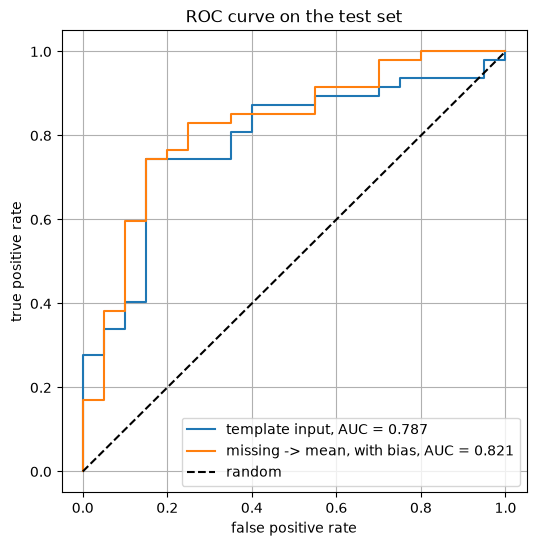

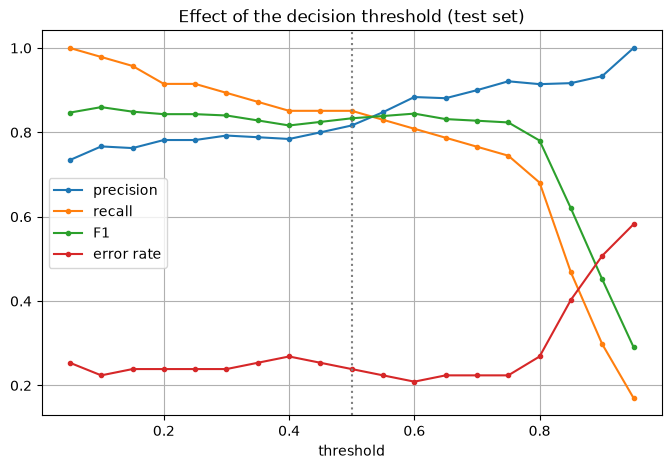

 阈值  precision  recall    F1   错误率
0.1      0.767   0.979 0.860 0.224
0.2      0.782   0.915 0.843 0.239
0.3      0.792   0.894 0.840 0.239
0.4      0.784   0.851 0.816 0.269
0.5      0.816   0.851 0.833 0.239
0.6      0.884   0.809 0.844 0.209
0.7      0.900   0.766 0.828 0.224
0.8      0.914   0.681 0.780 0.269
0.9      0.933   0.298 0.452 0.507

处理后模型测试错误率 0.2388，bootstrap 95% 区间 [0.134, 0.343]
全部预测为 1 的错误率减去模型错误率：区间 [-0.060, 0.179]


In [11]:
A_fin, B_fin = preprocess(X_train, X_test, 'missing')
random.seed(42)
w_fin = stocGradAscent(A_fin, y_train, numIter=500)
prob_fin = sigmoid(B_fin.dot(w_fin))
pred_fin = (prob_fin > 0.5).astype(int)
prob_raw = sigmoid(X_test.dot(w_raw))

print(pd.DataFrame({'模板原样': report(y_test, pred_raw), '处理后': report(y_test, pred_fin), '全部预测为1': report(y_test, pred_all1)}).round(4).to_string())

def roc_curve_points(y_true, score):
    order = np.argsort(-score, kind='stable')
    y_sorted = np.asarray(y_true)[order]
    tpr = np.r_[0, np.cumsum(y_sorted == 1) / (y_true == 1).sum()]
    fpr = np.r_[0, np.cumsum(y_sorted == 0) / (y_true == 0).sum()]
    return fpr, tpr

def auc_of(fpr, tpr):
    return np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2)

plt.figure(figsize=(6, 6))
for label, prob in [('template input', prob_raw), ('missing -> mean, with bias', prob_fin)]:
    fpr, tpr = roc_curve_points(y_test, prob)
    plt.plot(fpr, tpr, label='%s, AUC = %.3f' % (label, auc_of(fpr, tpr)))
    print('%-26s 手写 AUC %.4f，sklearn %.4f' % (label, auc_of(fpr, tpr), roc_auc_score(y_test, prob)))
plt.plot([0, 1], [0, 1], 'k--', label='random')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('ROC curve on the test set')
plt.legend()
plt.grid(True)
plt.show()

thresholds = np.arange(0.05, 0.96, 0.05)
sweep = []
for t in thresholds:
    r = report(y_test, (prob_fin > t).astype(int))
    sweep.append((t, r['precision'], r['recall'], r['F1'], 1 - r['accuracy']))
sweep = np.array(sweep)

plt.figure(figsize=(8, 5))
for k, name in enumerate(['precision', 'recall', 'F1', 'error rate'], start=1):
    plt.plot(sweep[:, 0], sweep[:, k], marker='.', label=name)
plt.axvline(0.5, color='gray', linestyle=':')
plt.xlabel('threshold')
plt.title('Effect of the decision threshold (test set)')
plt.legend()
plt.grid(True)
plt.show()

print(pd.DataFrame(sweep[[1, 3, 5, 7, 9, 11, 13, 15, 17]], columns=['阈值', 'precision', 'recall', 'F1', '错误率']).round(3).to_string(index=False))

rng = np.random.default_rng(0)
idx = rng.integers(0, len(y_test), size=(2000, len(y_test)))
e_fin = (pred_fin != y_test)[idx].mean(axis=1)
e_all1 = (pred_all1 != y_test)[idx].mean(axis=1)
diff = e_all1 - e_fin
print()
print('处理后模型测试错误率 %.4f，bootstrap 95%% 区间 [%.3f, %.3f]' % (e_fin.mean() if False else np.mean(pred_fin != y_test), *np.percentile(e_fin, [2.5, 97.5])))
print('全部预测为 1 的错误率减去模型错误率：区间 [%.3f, %.3f]' % tuple(np.percentile(diff, [2.5, 97.5])))

### 补充：一轮里每条样本被抽到几次

In [12]:
def epoch_counts(correct, m=299, repeats=200):
    counts = np.zeros(m)
    for _ in range(repeats):
        dataIndex = list(range(m))
        for i in range(m):
            randIndex = int(random.uniform(0, len(dataIndex)))
            counts[dataIndex[randIndex] if correct else randIndex] += 1
            del(dataIndex[randIndex])
    return counts / repeats

random.seed(0)
for correct in (True, False):
    c = epoch_counts(correct)
    print('%-28s 前 50 条平均 %.2f 次，最后 50 条平均 %.2f 次' % ('dataMatrix[dataIndex[randIndex]]' if correct else 'dataMatrix[randIndex]', c[:50].mean(), c[-50:].mean()))

dataMatrix[dataIndex[randIndex]] 前 50 条平均 1.00 次，最后 50 条平均 1.00 次
dataMatrix[randIndex]        前 50 条平均 2.77 次，最后 50 条平均 0.09 次
